<a href="https://colab.research.google.com/github/Cristina-as/Bike-Sharing-Demand-Prediction-using-Machine-Learning/blob/main/Analise_Acidentes_PRF_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Todos os anos, milhares de pessoas morrem nas rodovias federais do Braisl.
Mas nem todo acidente tem a mesma gravidade: alguns fatores aumentam muito a chance de um acidente terminar em morte.

Este projeto analisa os dados abertos da **Polícia Rodoviária Federal PRF** de 2025 para entender quais causas, horários, locais e condições da via estão associados aos acidentes mais letais, e propor recomendações a partir dos resultados.

### Perguntas que guiam a Análise:
1. **Causas:** Quais causas provocam mais acidentes? E quais são mais letais?
2. **Quando:** Em quais dias e horáriosos acidentes se concentram? Acidentes noturnos são mais graves?
3. **Onde:** Quais estados e rodovias têm mais acidentes e maior letalidade?
4. **Por quê:** o tipo de pista (simples, dupla ou múltipla) influencia a letalidade?

### Sobre os Dados:
**Fonte:** PRF, Dados Abertos, base "Acidentes 2025 (todas as cauas e tipos)"
**Abrangência:** apenas rodovias federais
**Tamanho:** 584.010 registros e 37 colunas, referentes a 72.529 acidentes e 177.479 pessoas envolvidas.

**Nota metodológica:** na base original, um mesmo acidente aparece em diversas linhas (uma para cada causa, vaículo e pessoa). Para evitar contagens infladas, foram criadas duas tabelas sem repetição: uma com **um registro por acidente** e outra com **um registro  por pessoa**.

### Métrica Principal

Para comparar grupos de tamanhos diferentes, foi usada a **letalidade**:
**Mortes a cada 100 acidentes** = (total de mortes / total de acidentes) * 100

### Ferramentas
Python . Pandas . Matplotlib . Seaborn . Google Colab

### Estrutura do Notebook

1. Carregamento e Exploração dos Dados
2. Limpeza e Preparação
3. Análise das Causas
4. Análise Temporal (Quando)
5. Análise Geográfica (Onde)
6. Tipo de Pista (Por Quê)
7. Conclusões e Recomendações


## Carregamento e Exploração dos Dados

In [24]:
# Manipulação e Análise de Dados

import pandas as pd
import numpy as np

# Visualização de Dados

import matplotlib.pyplot as plt
import seaborn as sns






In [25]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/acidentes2025_todas_causas_tipos.csv",
                 sep=";", encoding="latin1", decimal=",", low_memory=False)
df.shape

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(584010, 37)

In [26]:
# Primeiras Linhas

df.head()

# Mostra como os dados estão organizados


,id,pesid,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_principal,...,sexo,ilesos,feridos_leves,feridos_graves,mortos,latitude,longitude,regional,delegacia,uop
0,652468,1467636.0,2025-01-01,quarta-feira,00:30:00,PE,101.0,89.5,JABOATAO DOS GUARARAPES,Sim,...,Não Informado,0.0,0.0,0.0,0.0,-8.207607,-34.983720,SPRF-PE,DEL01-PE,UOP01-DEL01-PE
1,652468,1467635.0,2025-01-01,quarta-feira,00:30:00,PE,101.0,89.5,JABOATAO DOS GUARARAPES,Sim,...,Feminino,0.0,1.0,0.0,0.0,-8.207607,-34.983720,SPRF-PE,DEL01-PE,UOP01-DEL01-PE
2,652468,1467634.0,2025-01-01,quarta-feira,00:30:00,PE,101.0,89.5,JABOATAO DOS GUARARAPES,Sim,...,Masculino,0.0,1.0,0.0,0.0,-8.207607,-34.983720,SPRF-PE,DEL01-PE,UOP01-DEL01-PE
3,652468,1467637.0,2025-01-01,quarta-feira,00:30:00,PE,101.0,89.5,JABOATAO DOS GUARARAPES,Sim,...,Não Informado,0.0,0.0,0.0,0.0,-8.207607,-34.983720,SPRF-PE,DEL01-PE,UOP01-DEL01-PE
4,652469,1467628.0,2025-01-01,quarta-feira,00:50:00,SC,101.0,120.0,ITAJAI,Sim,...,Feminino,0.0,1.0,0.0,0.0,-26.912758,-48.711998,SPRF-SC,DEL04-SC,UOP04-DEL04-SC


In [27]:
# Colunas e Tipos de Dados

df.info()

# Repare em duas coisas:
# Dtype: object -> é texto, e int64 ou float64 são números.
# Colunas como data_inversa vão aparecer como texto e depois vamos convertê-las.
# Non-Null Count -> se for menor que o total de linhas, a colunatem valores faltando.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 584010 entries, 0 to 584009
Data columns (total 37 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      584010 non-null  int64  
 1   pesid                   527209 non-null  float64
 2   data_inversa            584010 non-null  object 
 3   dia_semana              584010 non-null  object 
 4   horario                 584010 non-null  object 
 5   uf                      584010 non-null  object 
 6   br                      582566 non-null  float64
 7   km                      582566 non-null  float64
 8   municipio               584010 non-null  object 
 9   causa_principal         584010 non-null  object 
 10  causa_acidente          584010 non-null  object 
 11  ordem_tipo_acidente     584010 non-null  int64  
 12  tipo_acidente           584010 non-null  object 
 13  classificacao_acidente  584003 non-null  object 
 14  fase_dia            

In [28]:
# Contar Valores Faltando

df.isnull().sum().sort_values(ascending=False)

,0
idade,105613
feridos_graves,56801
mortos,56801
feridos_leves,56801
pesid,56801
sexo,56801
estado_fisico,56801
tipo_envolvido,56801
ilesos,56801
id_veiculo,18617


In [29]:
# Contar Quantos Acidentes Existem de Verdade

print("Linhas:", len(df))
print("Acidentes únicos:", df["id"].nunique())

# A diferença entre os dois números mostra quantas linhas são repetições
# do mesmo acidente, por causa, veiculo ou pessoa.

Linhas: 584010
Acidentes únicos: 72529


In [30]:
# Ver o Resumo dos Números

df.describe()

# Confira se há valores estranhos, como idade 0 ou acima de 120.
# Esse tipo de erro é comum em dados reais.


,id,pesid,br,km,ordem_tipo_acidente,id_veiculo,ano_fabricacao_veiculo,idade,ilesos,feridos_leves,feridos_graves,mortos,latitude,longitude
count,584010.000000,5.272090e+05,582566.000000,582566.000000,584010.000000,5.653930e+05,565393.000000,478397.000000,527209.000000,527209.000000,527209.000000,527209.000000,584010.000000,584010.000000
mean,701065.091918,1.568126e+06,217.123176,277.977406,1.756710,1.251186e+06,1908.003633,39.752064,0.413671,0.339789,0.127052,0.052943,-17.938091,-47.082016
std,27198.821602,5.713756e+04,126.308297,236.066014,1.014753,4.539006e+04,450.197873,39.240287,0.492491,0.473638,0.333032,0.223920,7.828387,6.413207
min,652468.000000,1.467627e+06,10.000000,0.000000,1.000000,1.172934e+06,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-33.689326,-72.665988
25%,673002.000000,1.519574e+06,116.000000,83.600000,1.000000,1.212412e+06,2008.000000,27.000000,0.000000,0.000000,0.000000,0.000000,-24.551183,-51.124388
50%,703999.000000,1.567749e+06,174.000000,215.000000,1.000000,1.250968e+06,2014.000000,38.000000,0.000000,0.000000,0.000000,0.000000,-19.782186,-47.923903
75%,724320.000000,1.617790e+06,330.000000,433.400000,2.000000,1.291103e+06,2021.000000,49.000000,1.000000,1.000000,0.000000,0.000000,-11.436900,-42.791566
max,758186.000000,1.703928e+06,495.000000,1257.000000,14.000000,1.356558e+06,2025.000000,2024.000000,1.000000,1.000000,1.000000,1.000000,4.461419,-34.827891


## Limpeza e Preparação dos Dados

In [31]:
# Início da Limpeza dos Dados
# Convertendo as Datas e Criando Colunas Úteis

df["data_inversa"] = pd.to_datetime(df["data_inversa"])
df["mes"] = df["data_inversa"].dt.month
df["hora"] = pd.to_datetime(df["horario"], format="%H:%M:%S").dt.hour

# Criando Tabelas de Repetição, uma para cada tipo de pergunta:

acidentes = df.drop_duplicates(subset="id")
pessoas = df.dropna(subset=["pesid"]).drop_duplicates(subset=["id", "pesid"]) # linha por pessoa
print(len(acidentes), len(pessoas))



72529 177479


De acordo com a limpeza dos Dados, o total de acidentes registrados pela Polícia Rodoviária Federal de 2025 têm:
72.529 acidentes únicos;
177.479 pessoas envolvidas, uma média de cerca de 2,4 pessoas por acidente.


In [32]:
# Panorama Geral

print("Mortos:", pessoas["mortos"].sum())
print("Feridos_graves:", pessoas["feridos_graves"].sum())
print("Feridos_leves:", pessoas["feridos_leves"].sum())

Mortos: 6043.0
Feridos_graves: 20018.0
Feridos_leves: 63532.0


In [33]:
# Estados com mais acidentes

acidentes["uf"].value_counts().head(10)

,count
uf,
MG,9570
SC,8186
PR,7630
RJ,6428
RS,4899
SP,4683
BA,4108
GO,3196
PE,3013


In [34]:
# Acidentes por Dia da Semana e por Hora

acidentes["dia_semana"].value_counts()
acidentes["hora"].value_counts().sort_index()

,count
hora,
0,1508
1,1291
2,1160
3,1263
4,1595
5,2090
6,3169
7,4583
8,3765


## Análise das Causas

In [35]:
# Causas mais Frequentes e Causas que mais Matam

causas = (df.drop_duplicates(subset=["id", "causa_acidente"])
            .groupby('causa_acidente')["id"].count()
            .sort_values(ascending=False))
causas.head(10)

,id
causa_acidente,
Reação tardia ou ineficiente do condutor,15618
Ausência de reação do condutor,15423
Velocidade Incompatível,8714
Acessar a via sem observar a presença dos outros veículos,8110
Condutor deixou de manter distância do veículo da frente,6523
Ingestão de álcool pelo condutor,5900
Manobra de mudança de faixa,5081
Demais falhas mecânicas ou elétricas,3827
Condutor Dormindo,3330


In [36]:
# Vítimas ligadas à causa principal do acidente

principal = df[df["causa_principal"] == "Sim"]
mortes_causa = (principal.dropna(subset=["pesid"])
                   .drop_duplicates(subset=["id", "pesid"])
                   .groupby("causa_acidente")["mortos"].sum()
                   .sort_values(ascending=False))
mortes_causa.head(10)

,mortos
causa_acidente,
Transitar na contramão,961.0
Ausência de reação do condutor,855.0
Reação tardia ou ineficiente do condutor,597.0
Velocidade Incompatível,470.0
Acessar a via sem observar a presença dos outros veículos,421.0
Ultrapassagem Indevida,404.0
Pedestre andava na pista,252.0
Ingestão de álcool pelo condutor,223.0
Entrada inopinada do pedestre,209.0


O que os dados mostram:

1. Transitar na contramão é a causa que mais mata: 961 mortes. Faz sentido, por que costuma gerar colisõesfrontais, as mais violentas.

2. Ausência de reação (855) e reação tardia (597) somam mais de 1.450 mortes. Uma hipótese para investigar é que estejam ligadas a sono, cansaço ou distração ao volante.

3. Pedestres aparecem duas vezes: "andava na pista (252) e "entrada inopinada" (209). Juntas, essas causas somam 461 mortes, quase o mesmo que velocidade incompatível (470).

4. Quase todas as causas do top 10 são de comportamento humano, e não de falha da via ou do veículo.

## Taxa de Letalidade

In [37]:
# Uma causa pode matar muito só porque é muito frequente.
# Em quais causas o acidente tem mais chance de ser fatal?

acid_principal = principal.drop_duplicates(subset="id")
qtd_acidentes = acid_principal.groupby("causa_acidente")["id"].count()

letalidade = pd.DataFrame({
    "acidentes": qtd_acidentes,
    "mortes": mortes_causa
})
letalidade["mortes_por_100"] = (letalidade["mortes"] / letalidade["acidentes"] * 100).round(1)

#filtra causas com pelo menos 100 acidentes para evitar distorções
letalidade[letalidade["acidentes"] >= 100].sort_values("mortes_por_100", ascending=False).head()

# A coluna morts_por_100 mostra quantas pessoas morrem a cada 100 acidentes com aquela causa.


,acidentes,mortes,mortes_por_100
causa_acidente,,,
Suicídio (presumido),190,111.0,58.4
Pedestre andava na pista,606,252.0,41.6
Transitar na contramão,2475,961.0,38.8
Entrada inopinada do pedestre,667,209.0,31.3
Pedestre cruzava a pista fora da faixa,525,133.0,25.3


O que se apresenta até o momento:

Pedestres são vítimas mais vulneráveis. Três das cinco causas mais letais envolvem pedestres: andar na pista (41,6), entrada inesperada (31,3) e travessia fora da faixa (25,3). Sem a proteção de um veículo, qualquer atropelamento numa rodovia tende a ser grave.

A contramão é a causa mais crítica o páis. Ela é a única que aparece nos dois ranskings: é a que mais mata no total (38,8 mortes a cada 100 acidentes). Ou seja, é frequente e mortal. Esse é o insight principal do seu projeto.

Suícidio (presumido) aparece em 1º lugar, mas não é um acidente de trânsito no sentido comum. No portfólio, recomento separar essa categoria com uma nota explicando o motivo, e tratar o tema com sobriedade. Isso mostra maturidade analítica.

" A cada 100 acidentes por contramão, morrem cerca de 39 pessoas."

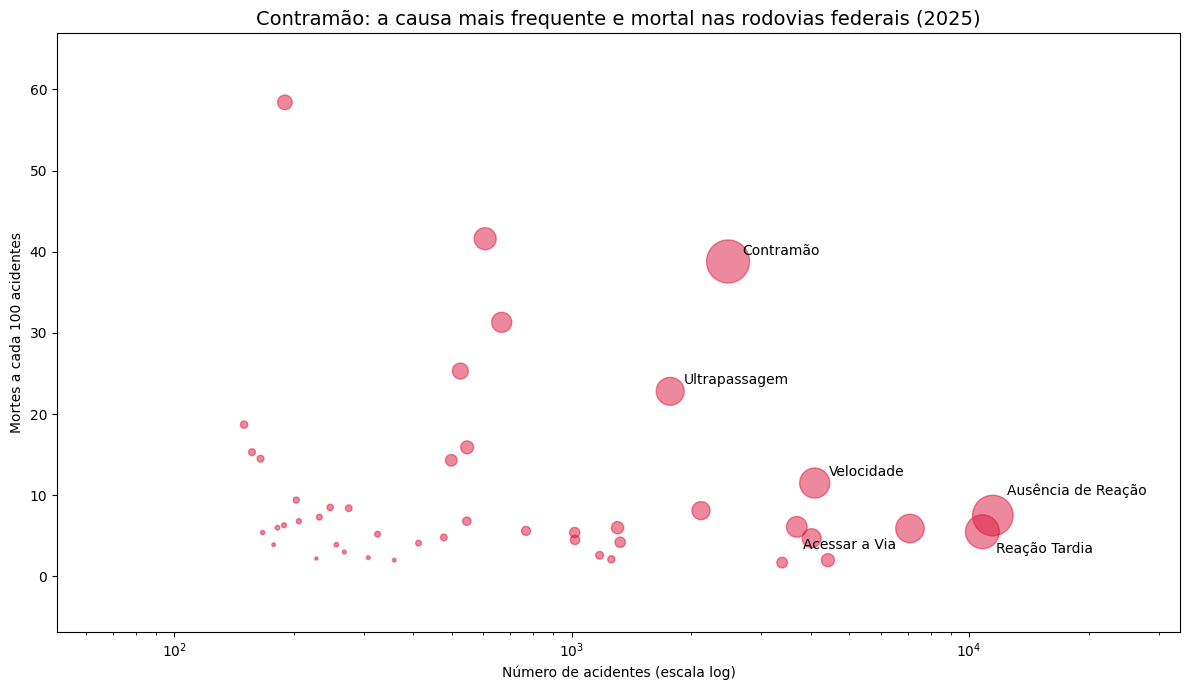

In [38]:
# Gráfico de Dispersão: frequênicia x letalidade

dados = letalidade[letalidade["acidentes"] >= 100]
dados = dados.drop("Suicidio (presumido)", errors="ignore")

plt.figure(figsize=(12, 7))
plt.scatter(dados["acidentes"], dados["mortes_por_100"],
            s=dados["mortes"], alpha=0.5, color="crimson")

# Trecho do Nome, Rótulo Curto, Deslocamento

rotulos = [
    ("contramão",          "Contramão",          (10, 5)),
    ("Ultrapassagem",      "Ultrapassagem",      (10, 5)),
    ("Velocidade",         "Velocidade",         (10, 5)),
    ("Ausência de Reação", "Ausência de Reação", (10, 15)),
    ("Reação Tardia",      "Reação Tardia",      (10, -15)),
    ("Acessar a via",      "Acessar a Via",      (-10, -15)),
    ]

for trecho, nome, desloc in rotulos:
    causa = [c for c in dados.index if trecho.lower() in c.lower()]
    if causa:
        c = causa[0]
        plt.annotate(nome, (dados.loc[c, "acidentes"], dados.loc[c, "mortes_por_100"]),
                     fontsize=10, xytext=desloc, textcoords="offset points",
                     ha="right" if desloc[0] < 0 else "left")

plt.xscale("log")
plt.title("Contramão: a causa mais frequente e mortal nas rodovias federais (2025)", fontsize=14)
plt.xlabel("Número de acidentes (escala log)")
plt.ylabel("Mortes a cada 100 acidentes")
plt.margins(x=0.25, y=0.15)
plt.tight_layout()
plt.savefig("frequencia_letalidade.png", dpi=300)
plt.show()



In [39]:
!cp frequencia_letalidade.png /content/drive/MyDrive/

## Análise Temporal

In [40]:
acidentes["dia_semana"].unique()

array(['quarta-feira', 'quinta-feira', 'sexta-feira', 'sábado', 'domingo',
       'segunda-feira', 'terça-feira'], dtype=object)

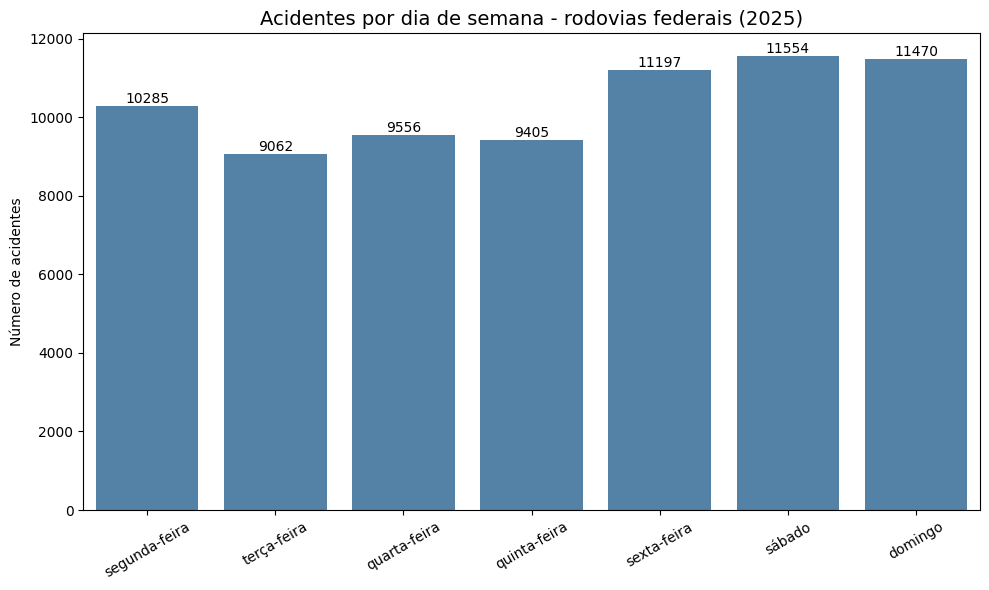

In [41]:
# Acidentes por dia da semana na ordem certa

ordem = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira",
         "sexta-feira", "sábado", "domingo"]

por_dia = acidentes["dia_semana"].value_counts().reindex(ordem)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=por_dia.index, y=por_dia.values, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Acidentes por dia de semana - rodovias federais (2025)", fontsize=14)
plt.xlabel("")
plt.ylabel("Número de acidentes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("acidentes_dia_semana.png", dpi=300)
plt.show()


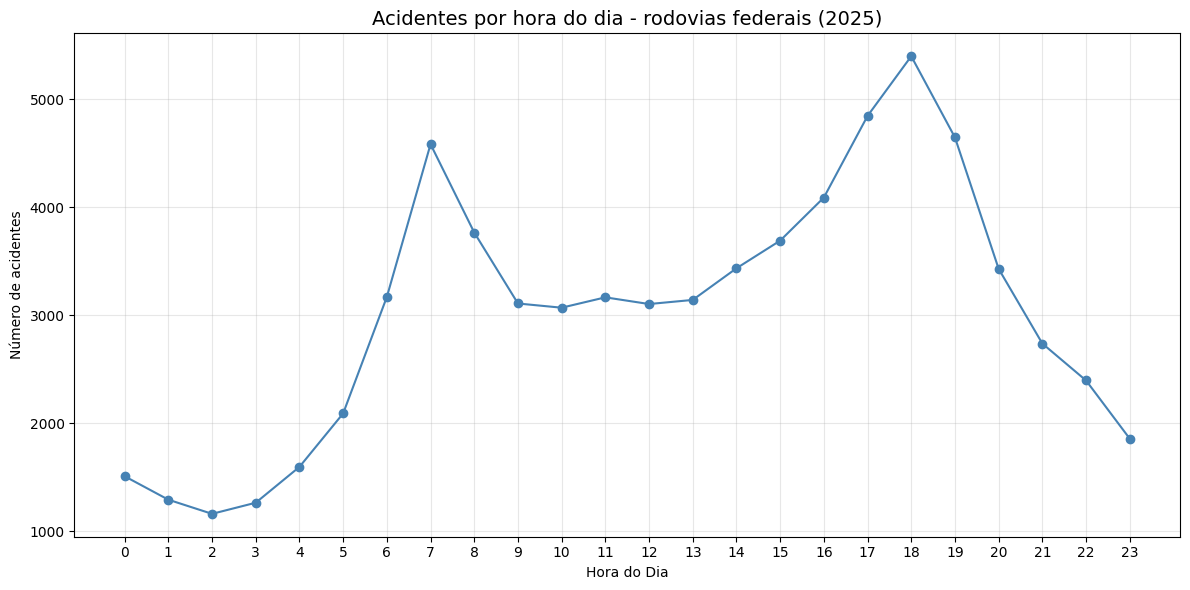

In [42]:
# Acidentes por hora do dia

por_hora = acidentes["hora"].value_counts().sort_index()

plt.figure(figsize=(12, 6))
plt.plot(por_hora.index, por_hora.values, marker="o", color="steelblue")
plt.title("Acidentes por hora do dia - rodovias federais (2025)", fontsize=14)
plt.xlabel("Hora do Dia")
plt.ylabel("Número de acidentes")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("acidentes_hora.png", dpi=300)
plt.show()


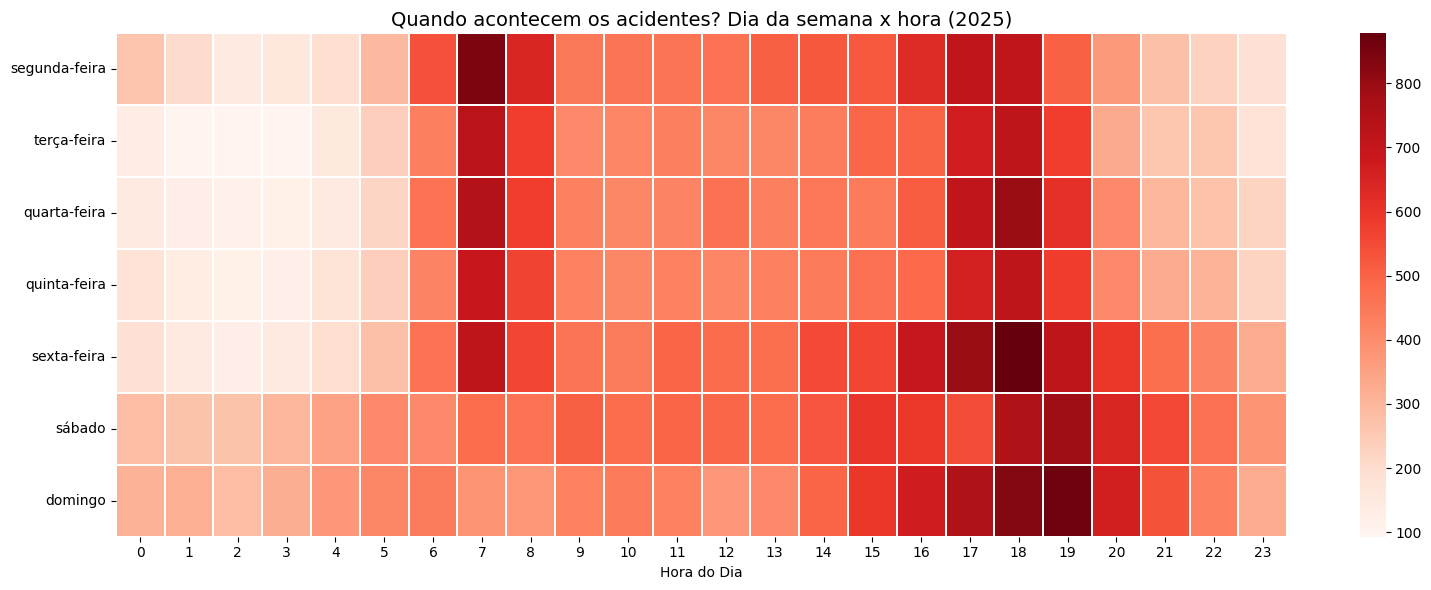

In [43]:
# Mapa de Calor de Dia x Hora

tabela = pd.crosstab(acidentes["dia_semana"], acidentes["hora"]).reindex(ordem)

plt.figure(figsize=(16, 6))
sns.heatmap(tabela, cmap="Reds", linewidths=0.3)
plt.title("Quando acontecem os acidentes? Dia da semana x hora (2025)", fontsize=14)
plt.xlabel("Hora do Dia")
plt.ylabel("")
plt.tight_layout()
plt.savefig("mapa_calor_dia_hora.png", dpi=300)
plt.show()


## Nos dias úteis, os acidentes seguem a rotina do trabalho. Nos fins de semana, seguem o lazer e as viagens.

In [44]:
# Horário exato de maior pico

tabela.stack().sort_values(ascending=False).head(5)

,,0
dia_semana,hora,
sexta-feira,18,878
domingo,19,863
segunda-feira,7,842
domingo,18,833
sexta-feira,17,797


In [45]:
# Letalidade por Fase do Dia

acid_fase = acidentes.groupby("fase_dia")["id"].count()
mortes_fase = pessoas.groupby("fase_dia")["mortos"].sum()

fase = pd.DataFrame({"acidentes": acid_fase, "mortes": mortes_fase})
fase["mortes_por_100"] = (fase["mortes"] / fase["acidentes"] * 100).round(1)
fase.sort_values("mortes_por_100", ascending=False)

,acidentes,mortes,mortes_por_100
fase_dia,,,
Amanhecer,3447,472.0,13.7
Plena Noite,24781,2892.0,11.7
Anoitecer,3926,288.0,7.3
Pleno dia,40375,2391.0,5.9


Os números mostram que:

De dia acontecem mais acidentes, mas a noite mata mais. O pleno dia concentra 56% dos acidentes (40.375), enquanto a plena noite tem 34% (24.781). Mesmo assim, a noite teve mais mortes: 2.892 contra 2.391 de dia.
Um acidente à noite é cerca de duas vezes mais letal: são 11,7 mortes a cada 100 acidentes, contra 5,9 de dia.
O amanhecer é o período mais letal de todos (13,7). Isso combina com a hipótese de sono e cansaço que apareceu nas causas ("ausência de reação"): motoristas que dirigiram a noite toda, somados `pouca luz.
Conferência: a soma dos acidentes por fase dá 72.529, o mesmo total de antes.

" À noite responde por 34% dos acidentes, mas por quase metade das mortes. Cada acidente noturno é duas vezes mais letal do que um diurno."

In [48]:
print(fase.index.tolist())
pct

['Amanhecer', 'Anoitecer', 'Plena Noite', 'Pleno dia']


,% dos acidentes
fase_dia,
Amanhecer,4.752582
Pleno Dia,NaN
Anoitecer,5.413007
Plena Noite,34.167023


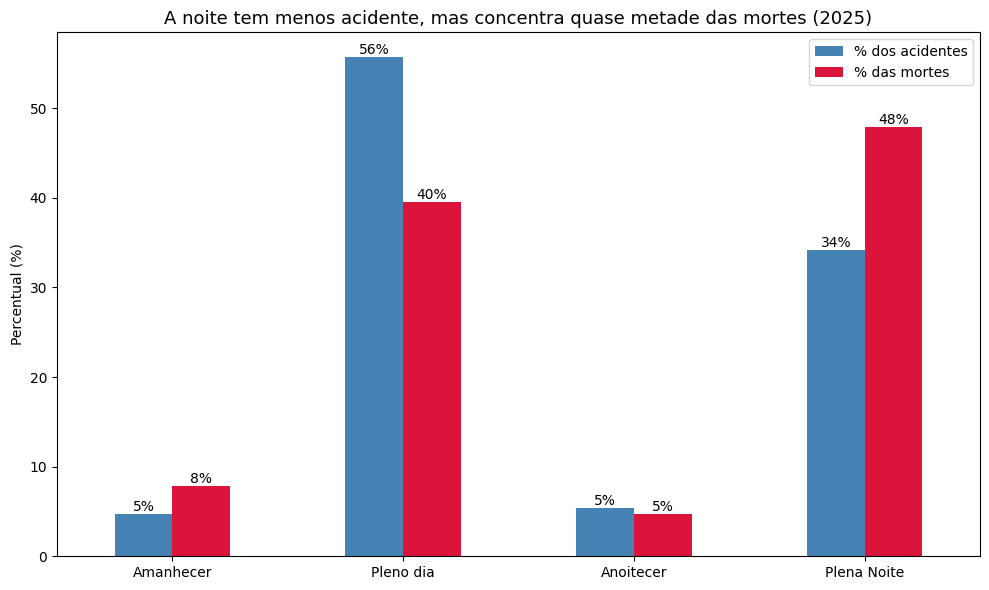

In [49]:
# Contraste de Acidentes x Mortes

ordem_fase = ["Amanhecer", "Pleno dia", "Anoitecer", "Plena Noite"]
pct = pd.DataFrame({
    "% dos acidentes": fase["acidentes"] / fase["acidentes"].sum() * 100,
    "% das mortes": fase["mortes"] / fase["mortes"].sum() * 100
}).reindex(ordem_fase)

ax = pct.plot(kind="bar", figsize=(10, 6), color=["steelblue", "crimson"], rot=0)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f%%")

plt.title("A noite tem menos acidente, mas concentra quase metade das mortes (2025)", fontsize=13)
plt.xlabel("")
plt.ylabel("Percentual (%)")
plt.tight_layout()
plt.savefig("fase_dia_acidentes_mortes.png", dpi=300)
plt.show()



## Análise Geográfica

In [52]:
# Estados com mais acidentes e mais Mortes.

acid_uf = acidentes.groupby("uf")["id"].count()
mortes_uf = pessoas.groupby("uf")["mortos"].sum()

uf = pd.DataFrame({"acidentes": acid_uf, "mortes": mortes_uf})
uf["mortes_por_100"] = (uf["mortes"] / uf["acidentes"] * 100).round(1)
uf.sort_values("acidentes", ascending=False).head(10)

,acidentes,mortes,mortes_por_100
uf,,,
MG,9570,765.0,8.0
SC,8186,434.0,5.3
PR,7630,593.0,7.8
RJ,6428,330.0,5.1
RS,4899,327.0,6.7
SP,4683,221.0,4.7
BA,4108,583.0,14.2
GO,3196,308.0,9.6
PE,3013,336.0,11.2


In [53]:
# As rodovias mais perigosas

acid_br = acidentes.groupby("br")["id"].count()
mortes_br = pessoas.groupby("br")["mortos"].sum()

br = pd.DataFrame({"acidentes": acid_br, "mortes": mortes_br})
br.index = "BR-" + br.index.astype(int).astype(str)
br.sort_values("mortes", ascending=False).head(10)

,acidentes,mortes
br,,
BR-101,13014,760.0
BR-116,11021,708.0
BR-153,2789,282.0
BR-40,3502,214.0
BR-163,2519,210.0
BR-316,1236,201.0
BR-230,1745,192.0
BR-381,3496,190.0
BR-364,2264,173.0


A base da PRF cobre somente Rodovias Federais.
São Paulo aparece com poucos acidentes porque boa parte do trpafego paulista passa por rodovias estaduais, que ficam fora dessa base.
Ond há mais acidentes não é onde se morre mais: no Nordeste e em rodovias como a BR-316, cada acidente é até três vezes mais letal do que no Sul e no Sudeste.

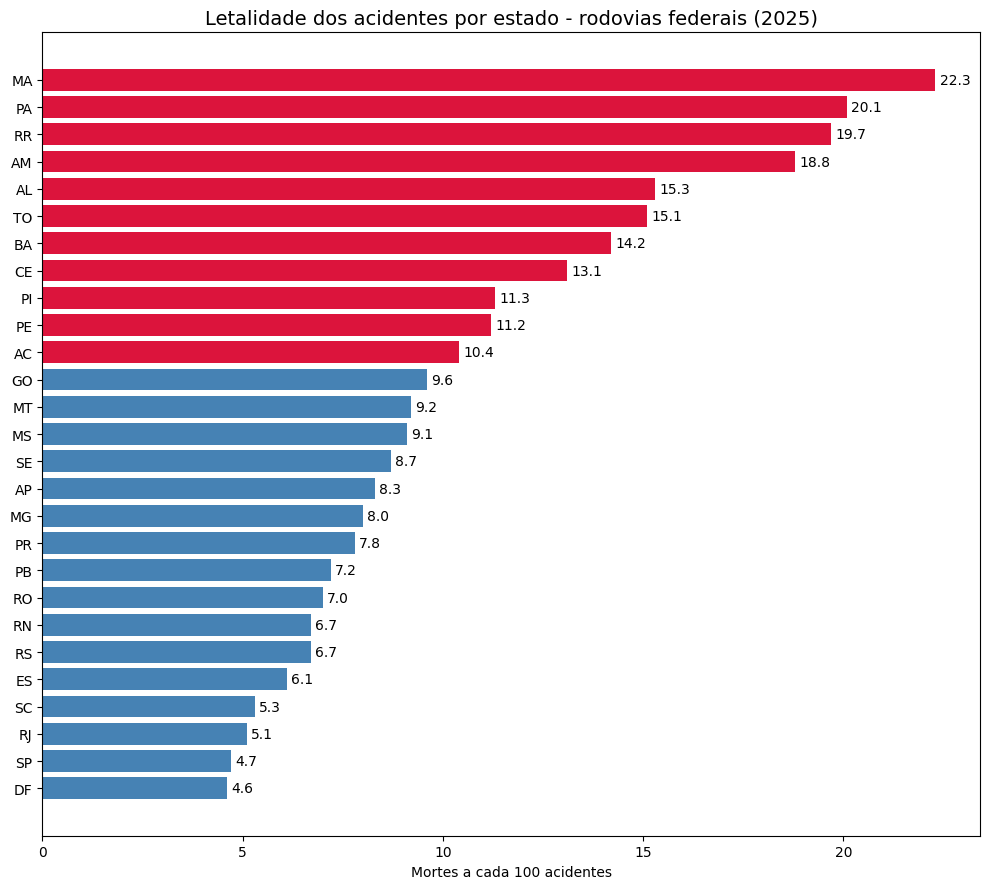

In [55]:
# Letalidade por Estado.

uf_ord = uf.sort_values("mortes_por_100")

plt.figure(figsize=(10, 9))
cores = ["crimson" if v >= 10 else "steelblue" for v in uf_ord["mortes_por_100"]]
ax = plt.barh(uf_ord.index, uf_ord["mortes_por_100"], color=cores)
plt.bar_label(ax, fmt="%.1f", padding=3)
plt.title("Letalidade dos acidentes por estado - rodovias federais (2025)", fontsize=14)
plt.xlabel("Mortes a cada 100 acidentes")
plt.tight_layout()
plt.savefig("letalidade_uf.png", dpi=300)
plt.show()

As barras vermelhas marcam os estados com 10 ou mais mortes a cada 100 acidentes, o que deixa o contraste regional evidente à primeira vista.

## Tipo de Pista

In [56]:
# Letalidade por tipo de pista

acid_pista = acidentes.groupby("tipo_pista")["id"].count()
mortes_pista = pessoas.groupby("tipo_pista")["mortos"].sum()

pista = pd.DataFrame({"acidentes": acid_pista, "mortes": mortes_pista})
pista["mortes_por_100"] = (pista["mortes"] / pista["acidentes"] * 100).round(1)
pista.sort_values("mortes_por_100", ascending=False)

,acidentes,mortes,mortes_por_100
tipo_pista,,,
Simples,34733,4143.0,11.9
Dupla,30782,1603.0,5.2
Múltipla,7014,297.0,4.2


In [57]:
# Os Estados mais letais têm pistas simples?

pct_simples = (acidentes.groupby("uf")["tipo_pista"]
               .apply(lambda x: (x == "Simples").mean() * 100).round(1))

comparacao = uf.join(pct_simples.rename("% pista simples"))
comparacao.sort_values("mortes_por_100", ascending=False).head(10)

,acidentes,mortes,mortes_por_100,% pista simples
uf,,,,
MA,1262,281.0,22.3,73.4
PA,1117,224.0,20.1,77.9
RR,142,28.0,19.7,90.8
AM,138,26.0,18.8,89.9
AL,629,96.0,15.3,61.8
TO,677,102.0,15.1,64.7
BA,4108,583.0,14.2,72.8
CE,1302,171.0,13.1,50.6
PI,1490,168.0,11.3,60.9


Pistas simples concentram 48% dos acidentes, mas 69% das mortes. A duplicação de rodovias aparece como uma das medidas com maior potencial para salvar vidas.

In [59]:
# Estados menos Letais.

comparacao.sort_values("mortes_por_100").head(5)


,acidentes,mortes,mortes_por_100,% pista simples
uf,,,,
DF,1011,47.0,4.6,13.1
SP,4683,221.0,4.7,16.5
RJ,6428,330.0,5.1,37.5
SC,8186,434.0,5.3,44.3
ES,2642,161.0,6.1,52.8


In [61]:
# Força da relação entre pista simples e letalidade com um único número.

comparacao["mortes_por_100"].corr(comparacao["% pista simples"]).round(2)

np.float64(0.69)

Correlação não é causalidade. A pista simples é um fator forte, mas outros também podem pesar, como a distância até hospitais, a iluminação, a fiscalização e o tipo de veículo.
Pernambuco, com letalidade alta e pouca pista simples, mostra isso.

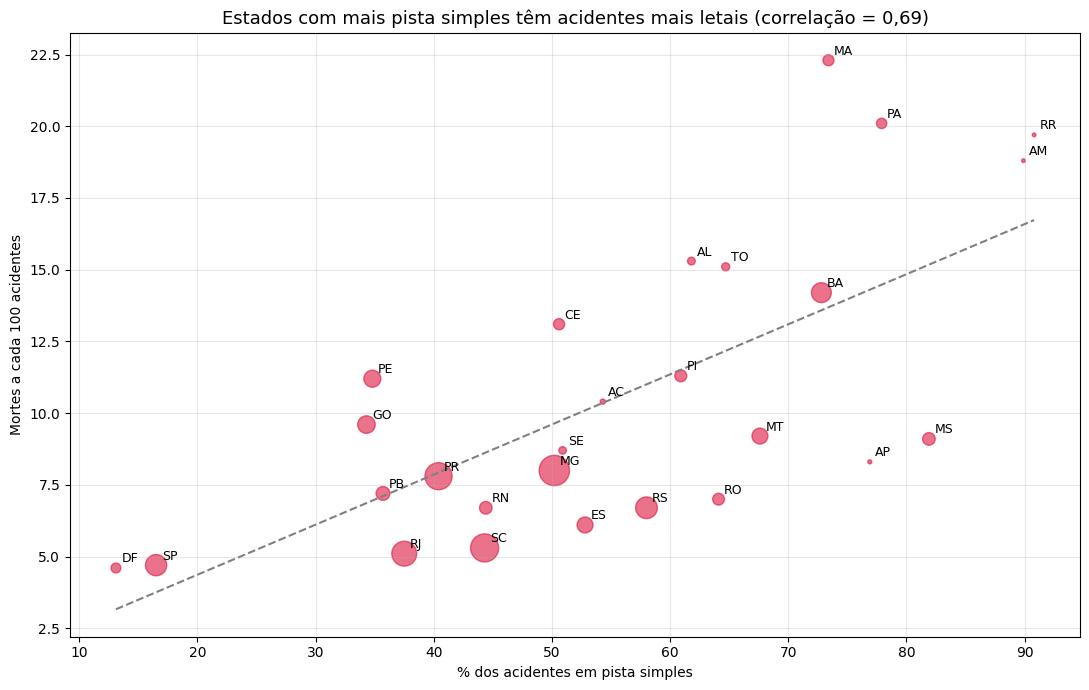

In [64]:
# Estados x Pista Simples

plt.figure(figsize=(11, 7))
plt.scatter(comparacao["% pista simples"], comparacao["mortes_por_100"],
            s=comparacao["acidentes"] / 20, alpha=0.6, color="crimson")

for estado in comparacao.index:
    plt.annotate(estado, (comparacao.loc[estado, "% pista simples"],
                          comparacao.loc[estado, "mortes_por_100"]),
                 fontsize=9, xytext=(4, 4), textcoords="offset points")

import numpy as np
x = comparacao["% pista simples"]
y = comparacao["mortes_por_100"]
a, b = np.polyfit(x, y, 1)
plt.plot(x.sort_values(), a * x.sort_values() + b, color="gray", linestyle="--", label="Tendência")
plt.legend

plt.title("Estados com mais pista simples têm acidentes mais letais (correlação = 0,69)", fontsize=13)
plt.xlabel("% dos acidentes em pista simples")
plt.ylabel("Mortes a cada 100 acidentes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pista_simples_letalidade_uf.png", dpi=300)
plt.show()

## Conclusões e Recomendações

Em 2025, as rodovias federais registraram 72.529 acidentes e 6.043 mortes.
A análise buscou responder: Quais fatores tornam um acidente mais letal?

Principais Achados:

1. A contramão é a causa mais crítica.
Foi a causa que mais matou (961 mortes) e uma das mais letais: cerca de
39 mortes a cada 100 acidentes. Falhas de reação do condutor (ausência de reação e reação tardia) somam mais de 1.450 mortes, o que sugere o peso do
sono, do cansaço e da distração.

2. Pedestres são as vítimas mais vulneráveis.
Três das causas mais letais envolvem pedestres, com até 42 mortes a cada 100 acidentes.

3. Os horários críticos seguem o ciclo do fim de semana.
Os picos de acidentes ocorrem na sexta às 18h, no domingo às 19h e na segunda às 7h: ida e volta das viagens e retorno ao trabalho.

4. A noite tem menos acidentes, mas mata mais.
A plena noite concentra 34% dos acidentes, mas 48% das mortes. Um acidente
noturno é cerca de 2 vezes mais letal que um diurno (11,7 contra 5,9 mortes a cada 100 acidentes). O amanhecer é o período mais letal (13,7).

5. A pista simples é o fator mais associado à letalidade.
Pistas simples concentram 48% dos acidentes, mas 69% das mortes, com
letalidade mais de 2 vezes maior que a das pistas duplas (11,9 contra 5,2).
Entre os estados, a correlação entre o % de acidentes em pista simples e a letalidade é de 0,69.

6. Onde há mais acidentes não é onde se morre mais.
Estados do Norte e do Nordeste, como Maranhão (22,3) e Pará (20,1), têm letalidade até 4 vezes maior que São Paulo (4,7) e o Distrito Federal (4,6).
A BR-316 se destaca: cerca de 16 mortes a cada 100 acidentes.

Recomendações:

* Priorizar a duplicação ou a separação física entre os sentidos nas rodovias de pista simples mais letais, especialmente no Norte e no Nordeste.
* Reforçar a fiscalização de ultrapassagens e contramão em pistas simples.
* Concentrar operações nas janelas críticas: sexta à tarde, domingo a noite e segunda de manhã.
* Combater a fadiga ao volante, com pontos de parada e campanhas para quem dirige à noite e de madrugada.
* Melhorar a segurança de pedestres, com iluminação, passarelas e travessias nos trechos urbanos das rodovias.

Limitações:

* A base cobre apenas rodovias federais. Estados com malha estadual extensa, como São Paulo, ficam sub-representados.
* Correlação não é causalidade: a pista simples está fortemente associada à letalidade, mas fatores como distância de hospitais, iluminação e fiscalização també podem influenciar.
* Estados com poucos acidentes (como RR e AM) têm taxas mais instáveis.
* Suicídio (presumido) foi excluído das análises de causas, por não se trata de acidente de trânsito no sentido usual.
* A análise considera apenas o ano de (2025).

**Fonte de Dados:** Polícia Rodoviária Federal, Dados Abertos (2025).

